# Malli 3 - Hienosäädetty (VGG16)

In [1]:
import keras
import matplotlib.pyplot as plt
import numpy as np
from keras import layers
from keras import models
from keras.models import Sequential
from keras.utils import image_dataset_from_directory
from scripts.notebook_scripts import collect_images, plot_images, plot_confusion_matrix
keras.utils.set_random_seed(42)

Tämä notebookti tutkii hienosäädettyä VGG16-mallia käyttäen samaa kuvadataa kuin edellisissä note bookeissa.

Tämän kokeen tarkoituksena on verrata mallin tuloksia edellisiin kahteen malliin ja selvittää, paraneeko vai heikkeneekö yleistyskyky.

## Valmistelut

Ensin lataamme tietomme omiin hakemistoihinsa ja määrittelemme niille:
- kuvan koon (224 x 224)
- eräkoko
- tunnisteet

Nyt data on jaettu oikein ja valmis käytettäväksi!

In [2]:
batch_size = 32
img_size = (224, 224) # every image is 224x224 pixels

train_dataset = image_dataset_from_directory(
    "dataset/train",
    image_size=img_size,
    batch_size=batch_size,
    label_mode="categorical"
 )

validation_dataset = image_dataset_from_directory(
    "dataset/validation",
    image_size=img_size,
    batch_size=batch_size,
    label_mode="categorical"
 )

test_dataset = image_dataset_from_directory(
    "dataset/test",
    image_size=img_size,
    batch_size=batch_size,
    label_mode="categorical"
 )

num_classes = len(train_dataset.class_names)

Found 175 files belonging to 5 classes.
Found 40 files belonging to 5 classes.
Found 35 files belonging to 5 classes.


Luomme VGG16:n konvoluutiopohjan, joka koostuu kaikista konvoluutio- ja maksimikasauskerroksista ilman lopullisia täysin yhdistettyjä (dense) luokittelukerroksia.

Aluksi asetamme ``trainable`` = ``False`` jäädyttääksemme alaosan kerrokset, jolloin niiden parametrit eivät päivity koulutuksen aikana. Takaisinsironnassa häviöfunktion gradienteista kulkevat edelleen kerrosten läpi, mutta niiden painot eivät päivity.

In [3]:
conv_base = keras.applications.vgg16.VGG16(
    weights="imagenet",
    include_top=False)
conv_base.trainable = False

conv_base.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, None, None, 3)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, None, None, 64) │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, None, None, 64) │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, None, None, 64) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, None, None,     │        73,856 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, None, None,     │       147,584 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, None, None,     │       295,168 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, None, None,     │       590,080 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, None, None,     │       590,080 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, None, None,     │     1,180,160 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │             

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

## Datan augmentointi

Tässä osassa käytämme samaa datan augmentointilogiikkaa kuin ensimmäisessä CNN-luokittelijassamme, jotta vertailu tulosten välillä on johdonmukaisempi.

In [4]:
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),    # Randomly flip images horizontally
        layers.RandomRotation(0.2),         # Randomly rotate images by up to 20%
        layers.RandomZoom(0.2),             # Randomly zoom images by up to 20%
        layers.RandomTranslation(0.1, 0.1), # Randomly translate images by up to 10% in both directions
        layers.RandomBrightness(0.2),       # Randomly adjust brightness by up to 20%
        layers.RandomContrast(0.2),         # Randomly adjust contrast by up to 20%
    ]
)

## Jäädytetty malli

Tässä vaiheessa rakennamme mukautetun luokittelijan esikoulutetun VGG16-konvoluutiopohjan päälle.

**Yleiskatsaus:**

1. Kuvat augmentoidaan yleistyvyyden parantamiseksi.
2. VGG16-esikäsittely sovelletaan.
3. Data kulkee konvoluutiopohjan läpi tunnistaakseen korkean tason piirteet.
4. Flatten muuntaa datan 1D-vektoriksi.
5. Tiheä kerros, jossa on `x` yksikköä, oppii datasetsidonnaisia kuvioita.
6. Dropoutia käytetään ylioppimisen vähentämiseen.
7. Lopulliset todennäköisyydet lasketaan ``softmax``-toiminnolla.

Tässä koulutamme vain ylimmät kerrokset, kun taas perusmalli pysyy jäädytettynä.

In [5]:
inputs = keras.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)
x = keras.applications.vgg16.preprocess_input(x)
x = conv_base(x)
x = layers.Flatten()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.4)(x)

outputs = layers.Dense(num_classes, activation="softmax")(x)

In [6]:
model = keras.Model(inputs, outputs)

## Koulutus

Malli käännetään (compiled) käyttäen:
- kategorista ristientropiaa häviöfunktiona
- RMSpropia optimoijana
- tarkkuutta (accuracy) arviointimittana

In [7]:
opt = keras.optimizers.RMSprop()
model.compile(loss="categorical_crossentropy",
              optimizer=opt,
              metrics=["accuracy"])

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 224, 224,  │          0 │ input_layer_1[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ sequential[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ sequential[0][0]  │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ sequential[0][0]  │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg16 (Functional)  │ (None, 7, 7, 512) │ 14,714,688 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 25088)     │          0 │ vgg16[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │  3,211,392 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 5)         │        645 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 17,926,725 (68.39 MB)

 Trainable params: 3,212,037 (12.25 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

Lisäämme ``ModelCheckpoint`` ja ``EarlyStopping`` takaisinkutsut koulutuksen aikana.

- ModelCheckpoint luo erillisen tarkistuspisteen, johon se tallentaa painot tietyin väliajoin. Siitä malli ja painot voidaan ladata jatkamaan koulutusta tallennetusta tilasta.

- EarlyStopping valvoo ennalta määriteltyä metriikkaa koulutuksen aikana ja pysäyttää prosessin, jos parannusta ei tapahdu useiden epochien ajan, mikä on määritetty `patience`-parametrillä.

In [8]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="feature_extraction_with_data_augmentation.keras",
        save_best_only=True,
        monitor="val_loss"
    ),
    keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True)
]

In [9]:
history = model.fit(
    train_dataset,
    epochs=30,
    validation_data=validation_dataset,
    callbacks=callbacks
)

Epoch 1/30


/Users/eliaseide/Neuroverkkoprojekti/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


6/6 ━━━━━━━━━━━━━━━━━━━━ 17s 3s/step - accuracy: 0.4743 - loss: 22.5337 - val_accuracy: 0.9750 - val_loss: 0.0347
Epoch 2/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 17s 3s/step - accuracy: 0.8914 - loss: 2.9210 - val_accuracy: 0.9750 - val_loss: 0.1358
Epoch 3/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 17s 3s/step - accuracy: 0.9257 - loss: 0.9964 - val_accuracy: 0.8500 - val_loss: 1.5518
Epoch 4/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 19s 3s/step - accuracy: 0.9371 - loss: 1.0084 - val_accuracy: 0.8250 - val_loss: 2.1816
Epoch 5/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 18s 3s/step - accuracy: 0.9600 - loss: 0.8572 - val_accuracy: 1.0000 - val_loss: 5.6624e-08
Epoch 6/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 18s 3s/step - accuracy: 0.9486 - loss: 0.6389 - val_accuracy: 1.0000 - val_loss: 9.6558e-07
Epoch 7/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 19s 3s/step - accuracy: 0.9543 - loss: 0.5902 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 8/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 19s 3s/step - accuracy: 0.9714 - loss: 0.2691 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Ep

## Visualisointi

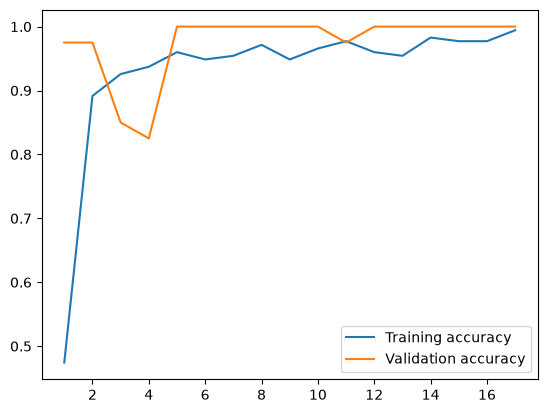

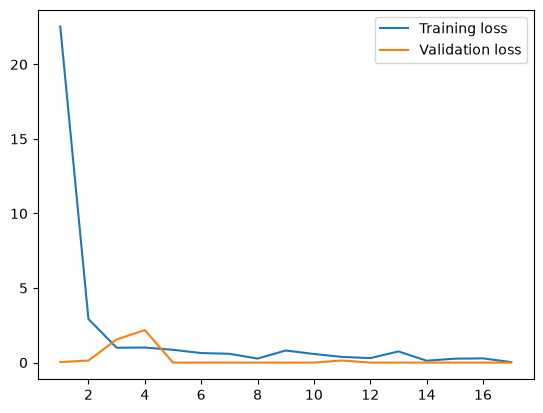

In [10]:
accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs = list(range(1, len(accuracy)+1))
plt.plot(epochs, accuracy, label="Training accuracy")
plt.plot(epochs, val_accuracy, label="Validation accuracy")
plt.legend()
plt.figure()
plt.plot(epochs, loss, label="Training loss")
plt.plot(epochs, val_loss, label="Validation loss")
plt.legend()
plt.show()

In [11]:
test_model = keras.models.load_model(
    "feature_extraction_with_data_augmentation.keras")
test_loss, test_acc = test_model.evaluate(test_dataset)
print(f"Test accuracy: {test_acc:3f}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 286ms/step - accuracy: 0.9714 - loss: 1.3622
Test accuracy: 0.971429


# Hienosäätö
Hienosäätö-vaiheessa esikoulutetun VGG16-mallin yläkerrokset avataan ja koulutetaan uudelleen käyttäen omaa tietojoukkoa.

Alemmat kerrokset jäävät jäädytetyiksi, koska ne sisältävät jo yleisiä visuaalisia piirteitä, kuten reunat ja tekstuurit.

Hienosäätö mahdollistaa mallin sopeutumisen korkeampitasoisiin piirteisiin erityisesti kohdeluokille, parantaen luokittelutulosta.

In [12]:
conv_base.trainable = True
for layer in conv_base.layers[:-4]:
    layer.trainable = False

In [13]:
finetuned_opt = keras.optimizers.RMSprop(learning_rate=1e-5)

model.compile(loss="categorical_crossentropy",
              optimizer=finetuned_opt,
              metrics=["accuracy"])

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 224, 224,  │          0 │ input_layer_1[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ sequential[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ sequential[0][0]  │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ sequential[0][0]  │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg16 (Functional)  │ (None, 7, 7, 512) │ 14,714,688 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 25088)     │          0 │ vgg16[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │  3,211,392 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 5)         │        645 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 17,926,725 (68.39 MB)

 Trainable params: 10,291,461 (39.26 MB)

 Non-trainable params: 7,635,264 (29.13 MB)

In [14]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="fine_tuning.keras",
        save_best_only=True,
        monitor="val_loss"),
    keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True)
]

In [15]:
history = model.fit(
    train_dataset,
    epochs=30,
    validation_data=validation_dataset,
    callbacks=callbacks)

Epoch 1/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 25s 4s/step - accuracy: 0.9829 - loss: 0.0888 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 2/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 24s 4s/step - accuracy: 0.9600 - loss: 0.2328 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 3/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 24s 4s/step - accuracy: 0.9714 - loss: 0.2585 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 4/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 23s 4s/step - accuracy: 0.9829 - loss: 0.2703 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 5/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 23s 4s/step - accuracy: 0.9771 - loss: 0.1487 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 6/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 23s 4s/step - accuracy: 0.9600 - loss: 0.2611 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 7/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 24s 4s/step - accuracy: 0.9714 - loss: 0.1054 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 8/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 73s 14s/step - accuracy: 0.9714 - loss: 0.1881 - val_accuracy: 1.000

In [16]:
test_model = keras.models.load_model("fine_tuning.keras")
test_loss, test_acc = test_model.evaluate(test_dataset)
print(f"Test accuracy: {test_acc:3f}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 265ms/step - accuracy: 0.9714 - loss: 1.8983
Test accuracy: 0.971429


Hienosäätö ei muuttanut testitarkkuutta: sekä jäädytetty malli että hienosäädetty malli saavuttivat **97,1 %** (34/35). Validointitarkkuus oli molemmissa vaiheissa jo 100 %, joten validointiaineisto ei pystynyt erottelemaan malleja toisistaan. Testihäviö kasvoi hienosäädössä (1,36 → 1,90), mikä viittaa siihen, että malli muuttui entistä varmemmaksi ennusteissaan myös silloin, kun se erehtyy.

In [17]:
num = len(test_dataset.file_paths)
print(f"\nNumber of pictures in test_dataset: {num}")
print(f"Ratio of predictions: {np.rint(num * test_acc)} : {np.rint(num - (num * test_acc))}")


Number of pictures in test_dataset: 35
Ratio of predictions: 34.0 : 1.0


## Ennusteiden analyysi

Jotta voimme analysoida mallin suorituskykyä tarkemmin, visualisoimme esimerkkejä:

- **Oikein luokitelluista kuvista**
- **Väärin luokitelluista kuvista**

Tämä auttaa ymmärtämään, missä malli toimii hyvin ja missä se kamppailee.

Tutkimalla väärin luokiteltuja kuvia voimme tunnistaa mahdollisia virheiden syitä, kuten:
- samanlaisia esineitä
- epätavallisia valaistusolosuhteita
- vaikeita kuvakulmia
- taustan häiriötekijöitä

Tämä tyyppinen laadullinen analyysi on tärkeä ymmärtääksemme mallin käyttäytymistä pelkkien tarkkuuslukujen lisäksi.

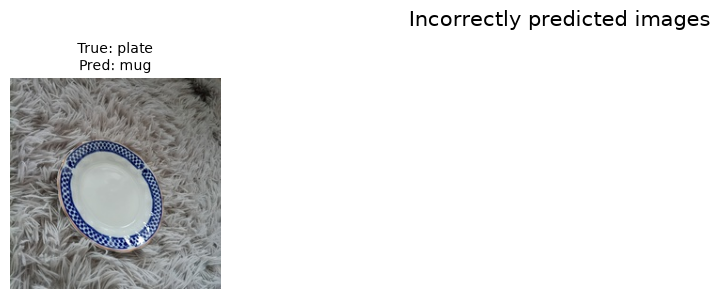

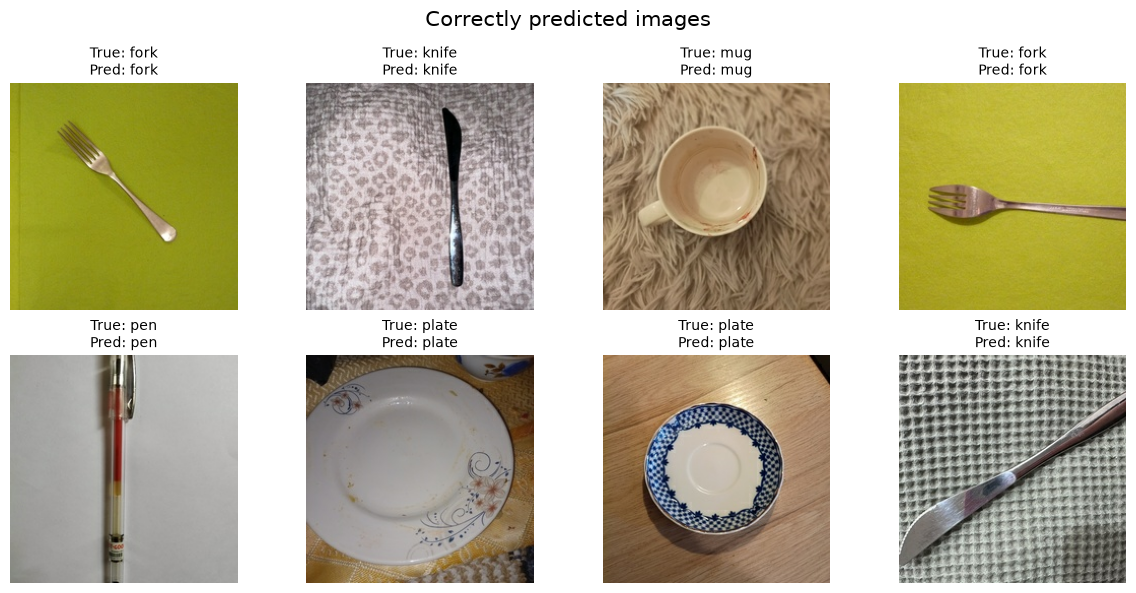

In [18]:
correct_images, wrong_images = collect_images(test_dataset, model)

plot_images(wrong_images, "Incorrectly predicted images")
plot_images(correct_images, "Correctly predicted images")

In [ ]:
cm = plot_confusion_matrix(correct_images + wrong_images, test_dataset.class_names)

## Yhteenveto

Hienosäädetty VGG16-malli saavutti **97,1 %** testitarkkuuden, mikä vastaa **34 oikein luokiteltua kuvaa 35:stä**.

Aiempiin malleihin verrattuna:

| Malli | Menetelmä | Testitarkkuus | Oikein / yhteensä |
|---|---|---:|---:|
| Malli 1 | Mukautettu CNN | 68,6 % | 24 / 35 |
| Malli 2 | Esikoulutettu VGG16 (piirteiden irrotus) | 97,1 % | 34 / 35 |
| Malli 3a | VGG16 jäädytettynä + augmentointi | 97,1 % | 34 / 35 |
| Malli 3b | Hienosäädetty VGG16 | 97,1 % | 34 / 35 |

Tulokset osoittavat, että siirto-oppiminen parantaa merkittävästi suorituskykyä verrattuna CNN:n kouluttamiseen alusta loppuun. Hienosäätö ei tässä aineistossa nostanut raakatarkkuutta Malli 2:n tasosta, koska esikoulutetut piirteet olivat jo erittäin sopivia tehtävään ja objektit ovat visuaalisesti melko selvästi erottuvia.

---
# Raportti: Kotitalousesineiden kuvantunnistus kolmella eri mallilla

## 1. Datasetin kuvaus

Projektin tehtävänä oli luokitella kuvia viiteen luokkaan: **fork (haarukka), knife (veitsi), mug (muki), pen (kynä) ja plate (lautanen)**. Kuvat on otettu itse, ja niitä on yhteensä **250 kappaletta, 50 jokaista luokkaa kohden**, eli aineisto on täysin tasapainoinen. Luokat ovat arkisia esineitä, mutta niiden joukossa on tarkoituksella myös keskenään visuaalisesti samankaltaisia esineitä (haarukka, veitsi ja kynä ovat kaikki ohuita ja pitkänomaisia), mikä tekee ongelmasta kiinnostavan.

Aineisto esikäsiteltiin skriptillä `PrepareDataset.py`:
- EXIF-kiertotiedon korjaus, RGB-muunnos, keskeltä rajaus neliöön ja skaalaus kokoon **224 × 224 px** (VGG16:n odottama syötekoko),
- **stratifioitu jako luokittain** suhteessa 70 / 15 / 15 %, jolloin jokaisessa joukossa on yhtä monta kuvaa kustakin luokasta,
- satunnaissiemen 42, joten jako on toistettavissa, ja jakotiedot tallennetaan tiedostoon `split_manifest.csv`.

| Joukko | Kuvia / luokka | Kuvia yhteensä |
|---|---:|---:|
| Koulutus (train) | 35 | 175 |
| Validointi (validation) | 8 | 40 |
| Testi (test) | 7 | 35 |

Kaikki kolme mallia käyttävät täsmälleen samaa jakoa, joten tulokset ovat suoraan vertailukelpoisia.

## 2. Mallit ja suorituskyvyn vertailu

**Malli 1: oma CNN.** Kolme konvoluutiolohkoa (16, 32 ja 64 suodatinta, MaxPooling ja Dropout 0,2), GlobalAveragePooling, Dense(64), Dropout(0,5) ja softmax. Parametreja on vain noin 28 000. Mallia koulutettiin alusta alkaen Adam-optimoijalla, ja koulutuksessa käytettiin voimakasta datan augmentointia sekä EarlyStoppingia (patience 5).

**Malli 2: esikoulutettu VGG16 (piirteiden irrotus).** ImageNetillä esikoulutettu VGG16 toimii jäädytettynä piirteiden irrottajana (`include_top=False`). Piirteet (7×7×512) lasketaan kerran, ja niiden päälle koulutetaan pieni luokittelija (Flatten, Dense(128), Dropout 0,5, softmax) RMSprop-optimoijalla 20 epochia.

**Malli 3: hienosäädetty VGG16.** Ensin koulutettiin luokittelija jäädytetyn VGG16:n päälle datan augmentoinnin kanssa (3a). Tämän jälkeen VGG16:n neljä viimeistä kerrosta (osa lohkosta 5) avattiin ja koulutettiin pienellä oppimisnopeudella (RMSprop, 1e-5) (3b). Koulutettavia parametreja oli tällöin noin 10,3 miljoonaa.

| Malli | Koulutettavia parametreja | Testitarkkuus | Oikein / 35 | Testihäviö |
|---|---:|---:|---:|---:|
| 1: oma CNN | ~28 tuhatta | 68,6 % | 24 | 0,83 |
| 2: VGG16, piirteiden irrotus | ~3,2 miljoonaa | 97,1 % | 34 | 0,47 |
| 3a: VGG16 jäädytettynä + augmentointi | ~3,2 miljoonaa | 97,1 % | 34 | 1,36 |
| 3b: hienosäädetty VGG16 | ~10,3 miljoonaa | 97,1 % | 34 | 1,90 |

Keskeiset havainnot:
1. **Siirto-oppiminen paransi tulosta selvästi:** esikoulutetut mallit saavuttivat noin 28 prosenttiyksikköä paremman tarkkuuden kuin tyhjästä koulutettu CNN, vaikka koulutusdataa oli vain 35 kuvaa luokkaa kohden.
2. **Mallien 2, 3a ja 3b välillä ei ole eroa testitarkkuudessa.** Kaikki tekivät testijoukossa vain yhden virheen. Yksi kuva vastaa 2,9 prosenttiyksikköä, joten näin pienellä testijoukolla (35 kuvaa) emme voi väittää yhden esikoulutetun mallin olevan toista parempi.
3. **Testihäviö kasvoi** mallista 2 malliin 3b (0,47 → 1,36 → 1,90) samalla kun tarkkuus pysyi samana. Mallit ovat siis ylivarmoja: kun ne erehtyvät, ne tekevät sen suurella varmuudella. Tarkkuus yksinään antaa tästä liian ruusuisen kuvan.
4. Väärin luokiteltuja kuvia on tarkasteltu työkirjojen lopun visualisoinneissa. Oletuksemme on, että sekaannukset syntyvät ennen kaikkea ohuiden, pitkänomaisten esineiden (haarukka, veitsi, kynä) välillä, mutta tätä ei ole mitattu virhematriisilla.

## 3. Kohtaamamme haasteet ja ratkaisut

| Haaste | Ratkaisu |
|---|---|
| **Pieni aineisto** (250 kuvaa): oman CNN:n ylisovittumisen riski on suuri. | Datan augmentointi (peilaus, kierto, zoom, siirto, kirkkaus, kontrasti), Dropout, pieni malli, EarlyStopping ja siirto-oppiminen. |
| **Pieni validointi- ja testijoukko:** 40 ja 35 kuvaa tekevät tuloksista kohinaisia, ja validointitarkkuus saavutti 100 %, jolloin se ei enää ohjannut koulutusta tehokkaasti. | Tulokset tulkittiin varovaisesti: raportoimme kuvamäärät prosenttien rinnalla emmekä väitä pienten erojen olevan merkittäviä. Parempi ratkaisu olisi ristiinvalidointi tai lisäkuvat. |
| **Toistettavuus ja datavuoto:** satunnaisjako olisi voinut muuttua ajokerrasta toiseen tai sekoittaa luokkia epätasaisesti. | Jako tehdään kiinteällä siemenellä (42), luokkakohtaisesti (stratifioitu) ja ennen mitään normalisointia. Normalisointitilastot lasketaan vain koulutusdatasta. Lisäksi `keras.utils.set_random_seed(42)` kaikissa työkirjoissa. |
| **Yhtenäinen syöte:** kuvat olivat eri kokoisia ja suuntaisia (EXIF). | Yhteinen esikäsittely: EXIF-kierto, keskirajaus ja skaalaus 224×224:ään. Oma CNN skaalaa pikselit väliin [0, 1] (`Rescaling`), VGG16 käyttää omaa `preprocess_input`-funktiotaan. |
| **Laskenta-aika:** VGG16:n hienosäätö on hidasta (noin 20 s / epoch ilman GPU:ta). | Mallissa 2 piirteet esilasketaan kerran. Hienosäädössä vain neljä viimeistä kerrosta avattiin, ja EarlyStopping lopetti koulutuksen ajoissa. |
| **Epävakaa hienosäätö:** liian suuri oppimisnopeus voisi tuhota esikoulutetut painot. | Luokittelija koulutettiin ensin jäädytetyn pohjan päälle, ja hienosäädössä käytettiin pientä oppimisnopeutta (1e-5). |
| **Kooditason ongelmat:** työkirjojen apufunktiot olivat kopioituina, ja mallin 2 funktio poikkesi muista. | Yhteiset `collect_images`- ja `plot_images`-funktiot siirrettiin tiedostoon `scripts/notebook_scripts.py`, jotta tulosten visualisointi toimii samoin kaikissa malleissa. |

## 4. Pohdinta: mallien soveltuvuus ongelmaan

**Oma CNN** on kevyt, nopea kouluttaa ja täysin ymmärrettävissä, eikä se vaadi ulkopuolisia malleja. Mutta kun dataa on vain 35 kuvaa per luokka, sen on opittava kaikki (reunat, muodot, tekstuurit) tyhjästä, ja tulos jää noin 69 %:iin. Se sopisi paremmin tilanteeseen, jossa dataa on tuhansia kuvia tai kuvat ovat hyvin erikoisia (esim. lääketieteelliset kuvat), eikä ImageNet-piirteistä olisi hyötyä.

**Esikoulutettu VGG16 (piirteiden irrotus)** osoittautui tähän ongelmaan parhaaksi kompromissiksi. Se saavutti korkeimman tarkkuuden (97,1 %) ja pienimmän testihäviön (0,47), ja koulutus on erittäin nopeaa, koska kuvat kulkevat VGG16:n läpi vain kerran. Haittapuolena on, ettei augmentointia voi käyttää, koska piirteet on laskettu valmiiksi, ja malli on iso (14,7 miljoonaa parametria) ja siksi raskas käyttää tuotannossa.

**Hienosäädetty VGG16** olisi teoriassa joustavin, koska se voi mukauttaa korkeamman tason piirteitä juuri näihin luokkiin. Tässä aineistossa se ei kuitenkaan tuonut mitään lisähyötyä (97,1 % kuten ennen hienosäätöä), mutta se on laskennallisesti kalliimpi ja kasvatti testihäviötä. Hienosäädöstä olisi todennäköisemmin hyötyä, jos kohdeluokat poikkeaisivat selvästi ImageNetin luokista tai jos aineisto olisi suurempi ja haastavampi. Meidän luokkamme (haarukka, muki, lautanen jne.) ovat sen sijaan hyvin lähellä ImageNetin sisältöä.

**Johtopäätös:** tämän projektin ongelmaan (5 selkeää esineluokkaa, pieni aineisto) paras valinta on esikoulutettu VGG16 piirteiden irrotuksella: yksinkertaisin ratkaisu, joka on yhtä tarkka kuin monimutkaisempi hienosäädetty malli. Jos ratkaisua laajennettaisiin, tärkeimmät kehityskohteet olisivat (1) enemmän ja monipuolisempia kuvia (eri taustat, valaistus ja kuvakulmat), jotta testitulokset olisivat luotettavampia, (2) ristiinvalidointi, (3) virhematriisi ja luokkakohtaiset tarkkuus-/saantimittarit sekä (4) kevyempi esikoulutettu malli (esim. MobileNet), jos mallia haluttaisiin käyttää mobiililaitteella.